In [16]:
import numpy as np
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.constants as cst

# Why do we need high-order mass assignment methods in cosmological simulations?

## The dark matter particle approximation
In cosmological N-body simulations, we want to describe the evolution of the dark matter density field under gravity. In N-body simulations, we assume that dark matter is composed of discretise particles with mass:

$$m_\mathrm{part} = \Omega_\mathrm{m}\,\rho_\mathrm{c,0} \left(\frac{L_\mathrm{B}}{N_\mathrm{part}}\right)^3$$

However, in reality, dark matter is a collisionless medium, which we describe mathematically through a continuous phase-space distribution function. But, simulating the gravitational evolution of every microscopic dark matter particle is computationally impossible. Instead, we introduce N-body particles, each representing a large number of dark matter particles. Therefore, we can approximate the continuous dark matter distribution using a finite number of massive particles and mathematically, we can describe the density field as:

$$ \rho(\mathbf{x}) = \sum_{i=1}^{N_p} m_\mathrm{part,i} \delta_D(\mathbf{x}-\mathbf{x}_i) $$
where:
- $m_\mathrm{part,i}$ is the mass of particle $i$
- $\mathbf{x}_i$ is its position
- $\delta_D$ is the Dirac delta function

This equation describes each dark matter particle as an infinitesimal point containing all its mass. Howerver, this introduce the problem that we __cannot directly represent Dirac delta functions on a finite numerical grid__. We instead need to distribute the particle mass onto the grid to calculate the density field. This is where mass assignment methods become important.

## Why should we distribute particle mass over several cells?
Imagine a particle moving across a regular grid and suppose its position changes slightly. For instance, initially, it is located near the centre of a cell _A_, it moves and crosses the boundary between cells _A_ and _B_. With the simplest mass assignment method, the __Nearest Grid Point (NGP)__, all its mass suddenly jumps from cell _A_ to cell _B_.

Physically, nothing dramatic happened, the particle moved only a tiny distance. However, from a numerical point of view, the density field experiences a discontinuous change and it introduces artificial fluctuations associated with the grid discretisation. A better approach is to distribute the particle mass over neighbouring cells, according to its distance from each cell centre. This is the motivation behind higher order mass-assignment such as:
- Cloud-in-Cell (CIC) (second order)
- Triangular-Shaped Cloud (TSC) (third order)
- Piecewise Cubic Spline (PCS) (fourth order)

An important physical interpretation: although an N-body particle is mathematically represented as a point mass, its mass assignment onto the mesh can be interpreted as replacing that point with a small cloud of mass. The cloud is not a physical extension of the dark matter particle. It is a numerical representation used to construct a smooth density field.

In [17]:
def mass_assignment(pos, N, method="CIC"):
    """
    Deposit particles onto a 3D grid using a mass assignment scheme.

    Parameters
    ----------
    pos : ndarray, shape (Npart, 3)
        Particle positions in grid coordinates [0, N).
        For example, x=2.5 corresponds to the middle of grid cells 2 and 3.

    N : int
        Number of grid cells per dimension.

    method : str
        Mass assignment method: NGP, CIC, TSC or PCS.

    Returns
    -------
    rho : ndarray, shape (N, N, N)
        Density grid. Each particle has unit mass.
    """

    # Associate each method with its B-spline order
    order = {"NGP": 1, "CIC": 2, "TSC": 3, "PCS": 4}[method]

    # Initialise the 3D density grid
    rho = np.zeros((N, N, N))

    # Loop over all particles
    for x, y, z in pos:

        if order == 1:  # NGP: Nearest Grid Point

            # Find the nearest grid cell
            indices = np.array([np.rint([x, y, z]).astype(int)])

            # All particle mass goes into this cell
            weights = np.ones((1, 3))

        else:

            # Find the grid cell immediately below the particle
            base = np.floor([x, y, z]).astype(int)

            indices = []
            weights = []

            # Loop over candidate neighbouring cells. The maximum support is 2 cells on either side (PCS)
            for i in range(base[0] - 1, base[0] + 3):
                for j in range(base[1] - 1, base[1] + 3):
                    for k in range(base[2] - 1, base[2] + 3):

                        # Distance between particle and grid cell centre
                        d = np.array([x-i, y-j, z-k])

                        # CIC: linear assignment kernel
                        if order == 2:
                            w = np.maximum(0, 1 - np.abs(d))

                        # TSC: quadratic assignment kernel
                        elif order == 3:
                            a = np.abs(d)
                            w = np.where(a < 0.5, 0.75 - a**2, np.where(a < 1.5, 0.5*(1.5-a)**2, 0))

                        # PCS: cubic assignment kernel
                        else:
                            a = np.abs(d)
                            w = np.where(a < 1, (4 - 6*a**2 + 3*a**3)/6, np.where(a < 2, (2-a)**3/6, 0))

                        # Store the grid cell indices
                        indices.append([i, j, k])

                        # Store the 1D weights for each dimension
                        weights.append(w)

            indices = np.asarray(indices)
            weights = np.asarray(weights)

        # Deposit the particle mass into the neighbouring cells
        for idx, w in zip(indices, weights):

            # Apply periodic boundary conditions. Negative indices and indices >= N wrap around the grid (boundary condition)
            i, j, k = idx % N

            # The 3D weight is the product of the three 1D weights (guarantees that the total mass is conserved)
            rho[i, j, k] += np.prod(w)

    return rho


## Understanding the different methods
Consider a one-dimensional grid for simplicity. Imagine a particle located between two grid cells.

### NGP – Nearest Grid Point
All the particle mass is assigned to the nearest grid cell, so that $\rho_j = m_i $ for the nearest cell $j$, and the particle contributes nothing to the other cells. Consequently, the density field changes discontinuously when the particle crosses the boundary between two cells.

### CIC – Cloud-in-Cell
The particle mass is distributed between the two neighbouring grid cells. The weights depend linearly on the distance from the particle to the grid centres. For a particle located between cells $j$ and $j+1$, we have:

$$ w_j = 1-f$$
$$w_{j+1}=f $$
where $f\in[0,1]$ represents the fractional position of the particle between the two cell centres. The mass is then conserved:

$$ w_j+w_{j+1}=1$$
In three dimensions, the particle contributes to \(2^3=8\) cells.

### TSC – Triangular-Shaped Cloud
Instead of distributing mass linearly between neighbouring cells, TSC uses a quadratic kernel. 
$$W_{\mathrm{TSC}}(r)= 
    \begin{cases}
        \frac{3}{4}-r^2                          & 0\leq r < \frac{1}{2} \\
        \frac{1}{2}\left(\frac{3}{2}-r\right)^2  & \frac{1}{2}\leq r < \frac{3}{2} \\
        0                                        & r\geq\frac{3}{2}
    \end{cases}
$$

The particle contributes to three cells in each dimension, corresponding to $3^3=27$ cells in three dimensions. This produces a smoother density field.

### PCS – Piecewise Cubic Spline
PCS uses a cubic kernel and distributes mass over four cells in each dimension. In three dimensions, this corresponds to \(4^3=64\) cells. The resulting density field is smoother still.

$$W_{\mathrm{PCS}}(r)=
    \begin{cases}
        \frac{1}{6}(4-6r^2+3r^3)            & 0\leq r < 1 \\
        \displaystyle \frac{1}{6}(2-r)^3    & 1\leq r < 2 \\
        0                                   & r\geq 2
    \end{cases}
$$

In the last three cases, the kernels are separable. Therefore, the 3D assignment weight is the product of the 1D weights:
$$ w_{ijk} = W(r_x)W(r_y)W(r_z) $$
where $r_x$, $r_y$ and $r_z$ are the relative distance between the particle position and the cell center in the $x$, $y$ and $z$-axis. They are defined as:
$$r_x=\frac{|x-x_i|}{\Delta x}, \qquad r_y=\frac{|y-y_j|}{\Delta x}, \qquad r_z=\frac{|z-z_k|}{\Delta x}$$

and the kernels are normalised so that the total gridded particle mass is conserved:
$$ \sum_{ijk} w_{ijk}=1 $$

# Example with random particle distribution

In [12]:
# Meshsize of the grid cells per dimension
N = 32

# Number of particles
Npart = 10000

# Generate uniformly distributed particle positions
np.random.seed(918)
pos = np.random.uniform(0, N, (Npart, 3))

# Apply the different mass assignment schemes

100%|█████████████████████████████████████████████| 4/4 [00:17<00:00,  4.28s/it]


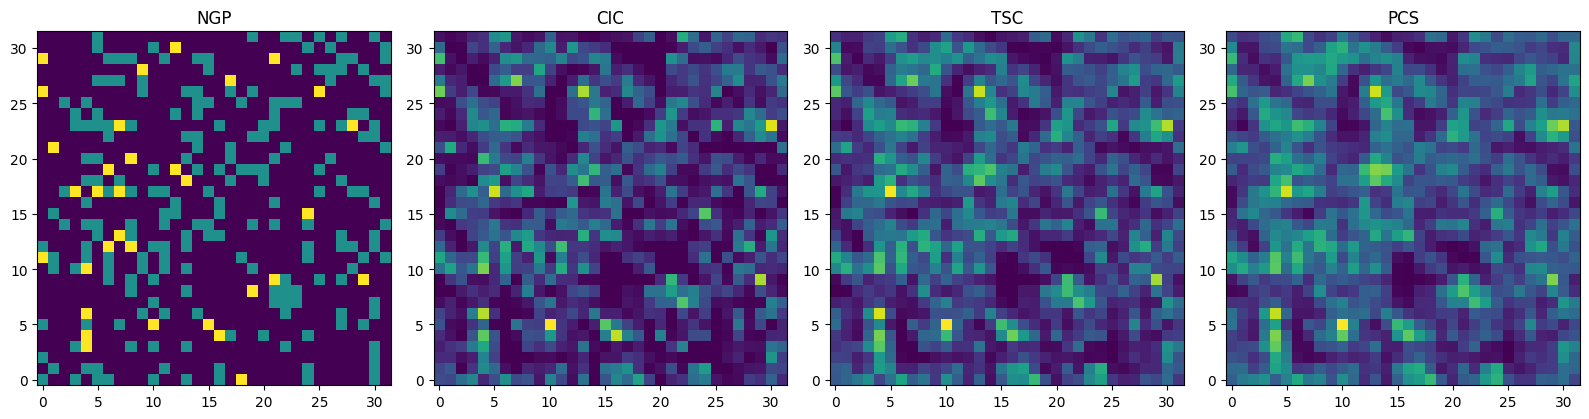

CPU times: user 17.4 s, sys: 5.79 ms, total: 17.4 s
Wall time: 17.4 s


(None, None)

<Figure size 640x480 with 0 Axes>

In [15]:
%%time

methods = ["NGP", "CIC", "TSC", "PCS"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, method in zip(axes, methods):

    # Deposit particle masses onto the grid
    rho = mass_assignment(pos, N, method)

    # Plot a 2D slice through the 3D density field
    ax.imshow(rho[:, :, N//2], origin="lower")

    ax.set_title(method)

plt.tight_layout()
plt.show(), plt.clf()

## Why is this important for gravitational calculations?
In many cosmological N-body simulations, to reduce the computatinal cost, gravity is calculated using a _Particle-Mesh (PM)_ approach. 

In short the procedure consist in particles that based on their positions, their masses are smoothed onto a regular grid to get the local density, $\rho$. Subsequently, the density constrast is calculated, $\rho-\bar{\rho}$. A FFT solver compute the Poisson equation and calculate the gravitational force on the grid, with the gravitational potential:

$$\boxed{ \nabla^2\Phi = 4\pi G(\rho-\bar{\rho})}$$
where $\bar{\rho}$ is the mean density. For then interpolate the gravitational force back to the particles, to compute the particle displacement and the changes in their velocities.

The problem is that the density field is now represented on a finite grid. Therefore, the mass assignment method influences the gravitational force calculation. For example, NGP introduces relatively strong grid-scale fluctuations, while CIC, TSC and PCS progressively reduce these effects. This is particularly important when studying e.g.: small-scale density fluctuations, dark matter halo formation, the matter power spectrum, the gravitational evolution near highly overdense regions, etc.

## The Fourier-space interpretation
There is another important numerical effect. Mass assignment introduces a smoothing kernel into the density field. In Fourier space, we can approximately write

$$ \delta_{\mathrm{grid}}(\mathbf{k}) = W(\mathbf{k})\delta(\mathbf{k}) $$
where $W(\mathbf{k})$ is the Fourier transform of the assignment kernel. For the different B-spline schemes:

$$ W_p(\mathbf{k}) = \prod_{i=x,y,z} \left[ \frac{\sin(k_i\Delta x/2)}{k_i\Delta x/2} \right]^p $$
where $p$ is the assignment order. Therefore:
- NGP suppresses small-scale modes relatively weakly.
- CIC introduces stronger smoothing.
- TSC and PCS introduce progressively stronger smoothing.

This means that higher-order methods produce smoother density fields, but they also suppress some genuine small-scale physical information. Important: Higher order does not automatically mean more accurate at every scale. The choice depends on the spatial resolution and the scientific quantity being measured. For power-spectrum calculations, one can correct for the assignment window (while also accounting for aliasing).